<a href="https://colab.research.google.com/github/Fidelisayogu/Fidelisayogu/blob/main/AI_Candidate_Evaluation_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

We will use:
- pandas and numpy — generate and manipulate candidate data.
- matplotlib and seaborn — create charts.
- scipy — statistical tests and correlation analysis.
- scikit-learn — later, for a basic candidate-job matching mod

In [1]:
pip install pandas numpy matplotlib seaborn scipy scikit-learn

We will simulate 500 candidates applying for data analyst jobs. Each candidate will have skill-match, interview, AI evaluation, human evaluation, and recruitment-stage data

In [2]:

import pandas as pd
import numpy as np

# Make the results reproducible
np.random.seed(42)

n = 500

# Generate synthetic candidate information
candidates = pd.DataFrame({
    "candidate_id": range(1, n + 1),
    "job_role": np.random.choice(
        ["Data Analyst", "BI Analyst", "Junior Data Scientist"],
        n
    ),
    "skills_match": np.random.randint(30, 101, n),
    "experience_years": np.random.randint(0, 7, n),
    "technical_score": np.random.randint(30, 101, n),
    "communication_score": np.random.randint(30, 101, n)
})

# Create a simulated reference score
candidates["reference_score"] = (
    0.40 * candidates["skills_match"]
    + 0.35 * candidates["technical_score"]
    + 0.15 * candidates["communication_score"]
    + 0.10 * (
        candidates["experience_years"] / 6 * 100
    )
)

# Simulate AI-generated scores with some random error
candidates["ai_score"] = np.clip(
    candidates["reference_score"]
    + np.random.normal(0, 8, n),
    0, 100
).round(1)

# Simulate independent human-review scores
candidates["human_score"] = np.clip(
    candidates["reference_score"]
    + np.random.normal(0, 6, n),
    0, 100
).round(1)

# Simulate recruitment stages
candidates["stage"] = pd.cut(
    candidates["reference_score"],
    bins=[-1, 45, 60, 75, 100],
    labels=[
        "Rejected",
        "Screening",
        "Interview",
        "Shortlisted"
    ]
).astype(str)

# Export the dataset
candidates.to_csv("candidate_evaluation.csv", index=False)

# Inspect the results
print(candidates.head())
print("Dataset shape:", candidates.shape)


   candidate_id               job_role  skills_match  experience_years  \
0             1  Junior Data Scientist            39                 1   
1             2           Data Analyst            48                 5   
2             3  Junior Data Scientist            87                 2   
3             4  Junior Data Scientist            30                 3   
4             5           Data Analyst            98                 1   

   technical_score  communication_score  reference_score  ai_score  \
0               47                   80        45.716667      60.6   
1               91                   44        65.983333      57.4   
2               66                   97        75.783333      73.0   
3               54                   50        43.400000      45.5   
4               77                   42        74.116667      83.3   

   human_score        stage  
0         58.8    Screening  
1         58.2    Interview  
2         71.9  Shortlisted  
3         44.5

#Clean and validate the data

In [3]:
df=pd.read_csv("candidate_evaluation.csv")
df.head()

,candidate_id,job_role,skills_match,experience_years,technical_score,communication_score,reference_score,ai_score,human_score,stage
0,1,Junior Data Scientist,39,1,47,80,45.716667,60.6,58.8,Screening
1,2,Data Analyst,48,5,91,44,65.983333,57.4,58.2,Interview
2,3,Junior Data Scientist,87,2,66,97,75.783333,73.0,71.9,Shortlisted
3,4,Junior Data Scientist,30,3,54,50,43.400000,45.5,44.5,Rejected
4,5,Data Analyst,98,1,77,42,74.116667,83.3,67.5,Interview


In [4]:
df.tail()

,candidate_id,job_role,skills_match,experience_years,technical_score,communication_score,reference_score,ai_score,human_score,stage
495,496,BI Analyst,40,4,52,92,54.666667,64.3,45.5,Screening
496,497,BI Analyst,67,5,76,76,73.133333,66.3,64.6,Interview
497,498,Data Analyst,35,5,44,86,50.633333,53.3,54.2,Screening
498,499,BI Analyst,52,1,54,74,52.466667,52.5,51.6,Screening
499,500,Junior Data Scientist,76,3,65,62,67.450000,75.5,63.9,Interview


In [5]:
df.shape

(500, 10)

In [6]:
df.isnull().sum()

,0
candidate_id,0
job_role,0
skills_match,0
experience_years,0
technical_score,0
communication_score,0
reference_score,0
ai_score,0
human_score,0
stage,0


In [7]:
df.candidate_id.duplicated().sum()

np.int64(0)

In [9]:
score_columns = ["skills_match", "technical_score", "communication_score", "experience_years", "reference_score", "ai_score", "human_score"]
df[score_columns].describe()

,skills_match,technical_score,communication_score,experience_years,reference_score,ai_score,human_score
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,63.452000,64.892000,62.360000,2.946000,62.357000,62.261400,62.033800
std,20.546826,20.473756,20.228217,2.052196,11.786697,13.914716,13.317004
min,30.000000,30.000000,30.000000,0.000000,29.850000,19.200000,25.500000
25%,46.000000,47.000000,45.000000,1.000000,53.479167,52.400000,52.775000
50%,63.000000,66.000000,61.000000,3.000000,61.883333,62.100000,62.750000
75%,81.000000,82.000000,80.000000,5.000000,71.316667,72.800000,71.300000
max,100.000000,100.000000,100.000000,6.000000,91.883333,100.000000,100.000000


In [15]:
df['stage'].value_counts()

,count
stage,
Interview,195
Screening,192
Shortlisted,81
Rejected,32


 # **Conducting the main analyses**



##**Analysis A — AI evaluation quality**

**Compare ai_score against human_score and reference_score. Calculate mean absolute error (MAE), correlation, and average score differences.
Question: Does the AI score closely track the benchmark, or does it systematically over-score or under-score candidates?**

In [26]:
from sklearn.metrics import mean_absolute_error as mae

ai_mae = mae(
    df["reference_score"],
    df["ai_score"]
)

human_mae = mae(
    df["reference_score"],
    df["human_score"]
)

score_correlation=df[
    ['ai_score','human_score','reference_score']
    ].corr()

print(f"AI mean absolute error: {ai_mae:.2f}")
print(f"Human mean absolute error: {human_mae:.2f}")
print("\nScore correlations:")
print(score_correlation.round(2))


AI mean absolute error: 6.20
Human mean absolute error: 4.80

Score correlations:
                 ai_score  human_score  reference_score
ai_score             1.00         0.75             0.83
human_score          0.75         1.00             0.90
reference_score      0.83         0.90             1.00


Bottom line: The humans outperform the AI on both error and correlation, but the AI is reasonably close, and the pattern suggests it may be improvable through calibration.

#**Analysis B — Candidate-job matching**
**Compare skills match and technical_score across job roles. Identify where candidates have strong or weak alignment with the role requirements.
Question: Which role has the strongest average skills match in this simulated dataset?**

In [28]:

role_analysis = (
    df.groupby("job_role")
    .agg(
        candidate_count=("candidate_id", "count"),
        avg_skills_match=("skills_match", "mean"),
        avg_technical_score=("technical_score", "mean")
    )
    .sort_values("avg_skills_match", ascending=False)
    .round(2)
)

print(role_analysis)


                       candidate_count  avg_skills_match  avg_technical_score
job_role                                                                     
Data Analyst                       168             63.85                67.17
Junior Data Scientist              165             63.84                64.74
BI Analyst                         167             62.67                62.75


Finding: Data Analyst has the highest average skills-match score at 63.85, although Junior Data Scientist is nearly identical at 63.84. Data Analyst also has the highest average technical score at 67.17.

Business interpretation: In this simulation, Data Analyst candidates show the strongest average alignment with job requirements. However, the difference in skills match between the top two roles is negligible. We should not claim that the difference is statistically or practically meaningful without further analysis.

#**Analysis C — Recruiting funnel**
**Count candidates at each stage and calculate the proportion reaching the interview and shortlist stages.
Question: Where does the largest drop off occur?**

In [36]:

stage_order = [
    "Rejected",
    "Screening",
    "Interview",
    "Shortlisted"
]

stage_counts = (
    candidates["stage"]
    .value_counts()
    .reindex(stage_order, fill_value=0)
)

print(stage_counts)


stage
Rejected        32
Screening      192
Interview      195
Shortlisted     81
Name: count, dtype: int64


#**Analysis D — Evaluation consistency**
**Calculate ai_score - human_score, examine the distribution of differences, and compare errors across job roles.
Question: Does the AI agree equally well across all three roles?**

In [37]:

candidates["ai_human_difference"] = (
    candidates["ai_score"] - candidates["human_score"]
)

consistency = (
    candidates.groupby("job_role")
    .agg(
        candidate_count=("candidate_id", "count"),
        avg_score_difference=("ai_human_difference", "mean"),
        mean_absolute_difference=(
            "ai_human_difference",
            lambda x: x.abs().mean()
        )
    )
    .round(2)
)

print(consistency)


                       candidate_count  avg_score_difference  \
job_role                                                       
BI Analyst                         167                  0.34   
Data Analyst                       168                 -0.69   
Junior Data Scientist              165                  1.05   

                       mean_absolute_difference  
job_role                                         
BI Analyst                                 8.72  
Data Analyst                               7.24  
Junior Data Scientist                      6.99  


- Junior Data Scientist: The AI scores about 1.05 points higher than human
reviewers on average.
- Data Analyst: The AI scores about 0.69 points lower on average.
- BI Analyst: The AI-human gap is largest, with a mean absolute difference of 8.72 points.

Finding: In this simulation, AI-human score agreement varies across job roles. BI Analyst has the largest average absolute difference, making it a useful area for further investigation.

However, score differences alone do not prove the AI is biased or inaccurate. Human reviewers can also disagree with one another. In a real project, we would need multiple independent reviewers, a clearly defined scoring rubric, and appropriate agreement metrics.

#**VISUALIZATION FOR THE FOUR ANALYSIS**

##**AI score vs reference score**
**This scatter plot shows whether AI-generated scores closely track the simulated benchmark. The dashed diagonal represents perfect agreement**

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>
<function figure at 0x7f2af2b6b380>


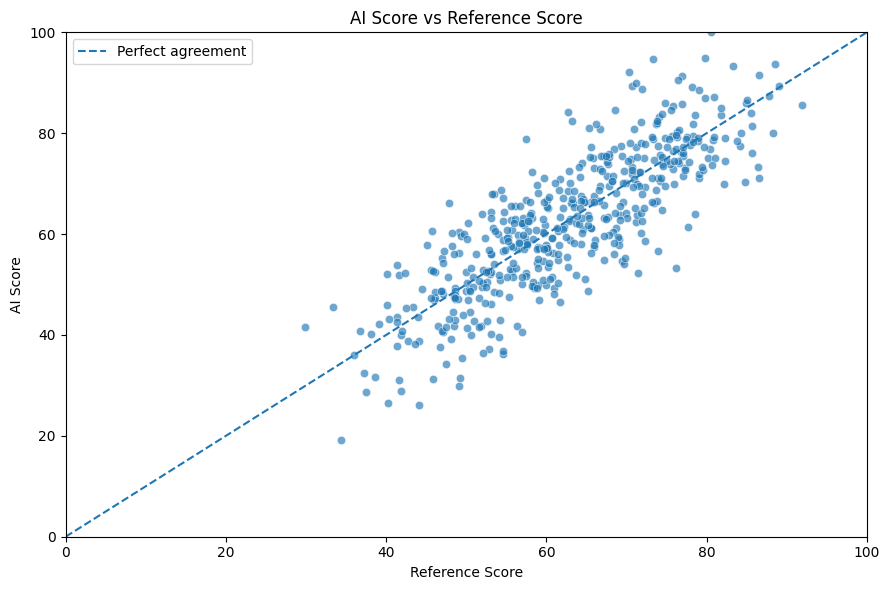

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print(plt)
print(plt.figure)

# Create a scatterplot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="reference_score",
    y="ai_score",
    alpha=0.65
)

# Perfect-agreement line
plt.plot(
    [0, 100], [0, 100],
    linestyle="--",
    label="Perfect agreement"
)

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.title("AI Score vs Reference Score")
plt.xlabel("Reference Score")
plt.ylabel("AI Score")
plt.legend()
plt.tight_layout()
plt.show()


#**Average skills match by job role**
**This bar chart compares the average skills-match score for each role.**

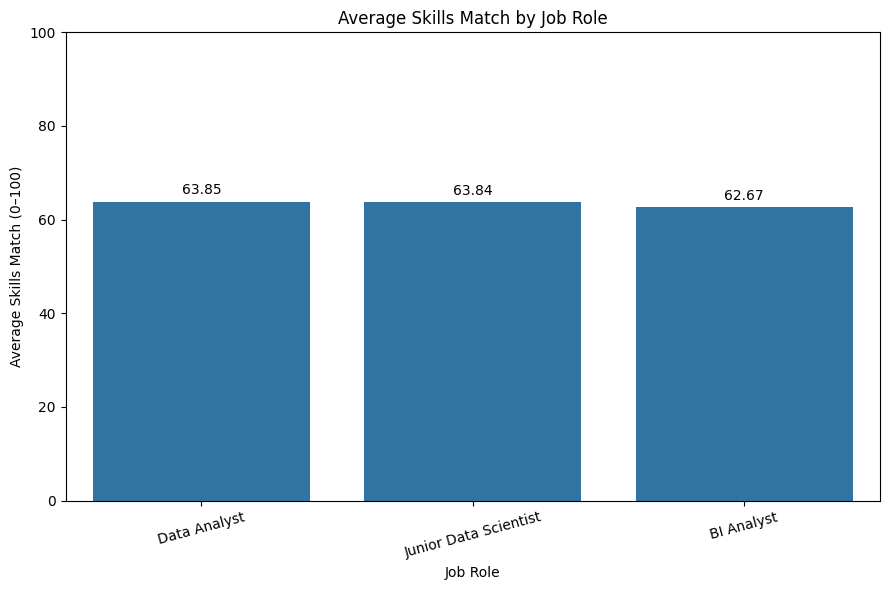

In [45]:

role_scores = (
    df.groupby("job_role", as_index=False)
    ["skills_match"].mean()
    .sort_values("skills_match", ascending=False)
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=role_scores,
    x="job_role",
    y="skills_match"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title("Average Skills Match by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Average Skills Match (0–100)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


##**Candidate stage distribution**
**Your current stage column contains score-based categories, not actual hiring-stage transitions. This chart visualizes that distribution, but it should not be presented as a genuine recruitment funnel.**

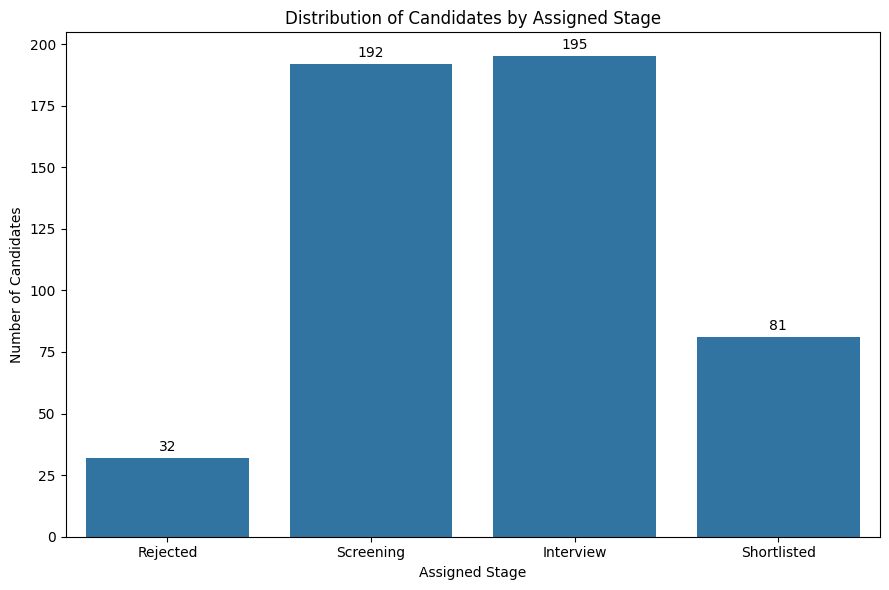

In [46]:

stage_order = [
    "Rejected",
    "Screening",
    "Interview",
    "Shortlisted"
]

stage_counts = (
    candidates["stage"]
    .value_counts()
    .reindex(stage_order, fill_value=0)
    .reset_index()
)

stage_counts.columns = ["stage", "candidate_count"]

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=stage_counts,
    x="stage",
    y="candidate_count"
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Distribution of Candidates by Assigned Stage")
plt.xlabel("Assigned Stage")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()


#**AI vs human scoring differences by role**
**This box plot shows how the difference between AI and human scores varies across job roles.**

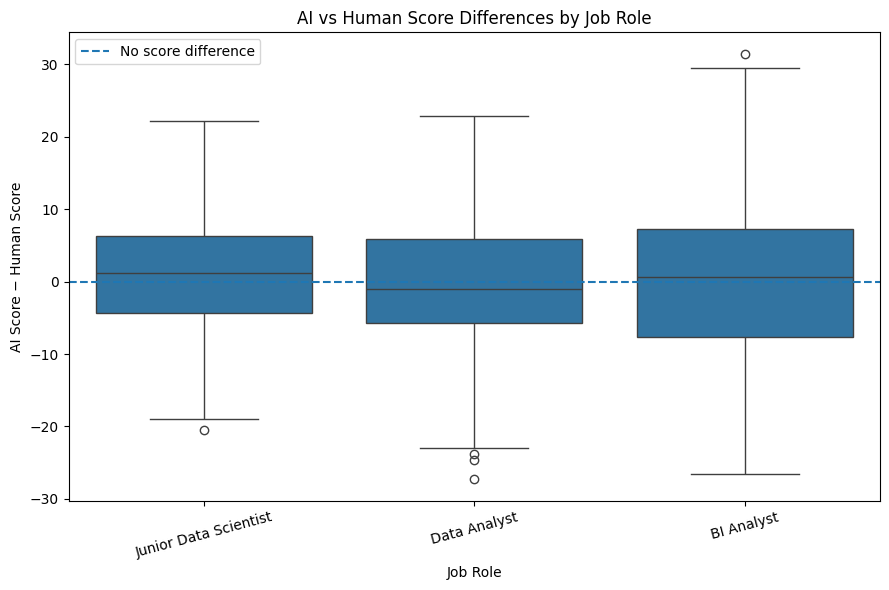

In [47]:

candidates["ai_human_difference"] = (
    candidates["ai_score"] - candidates["human_score"]
)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=candidates,
    x="job_role",
    y="ai_human_difference"
)

plt.axhline(0, linestyle="--", label="No score difference")

plt.title("AI vs Human Score Differences by Job Role")
plt.xlabel("Job Role")
plt.ylabel("AI Score − Human Score")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


#DASHBOARD SUMMARY

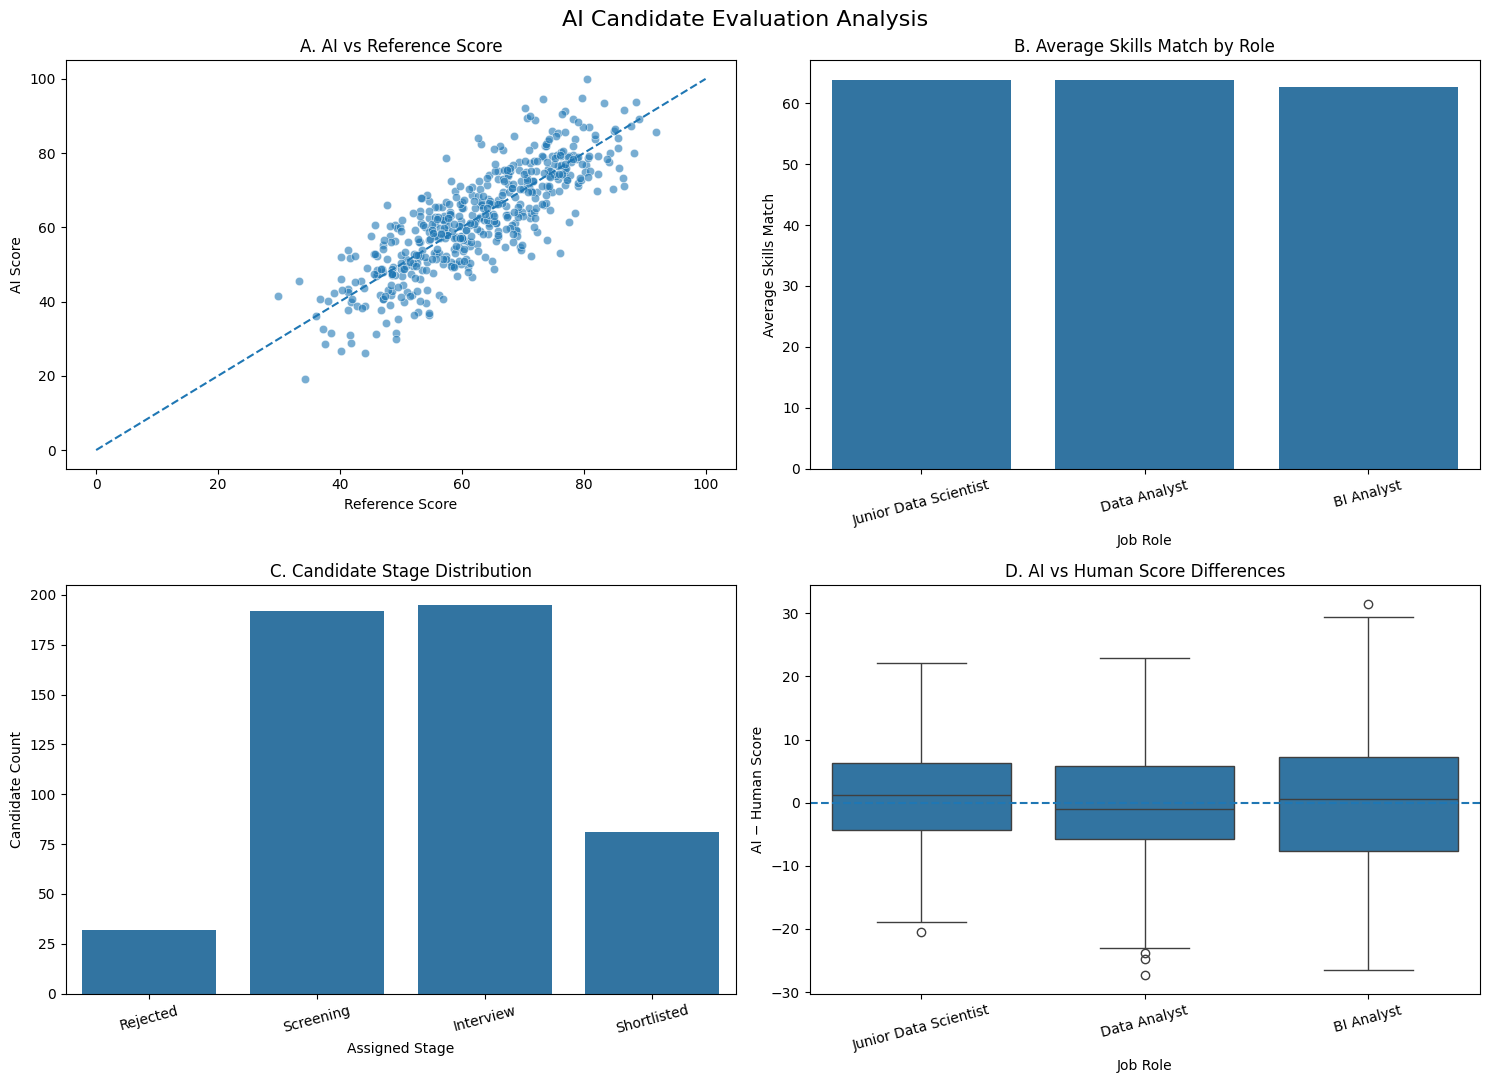

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart A: AI vs reference
sns.scatterplot(
    data=candidates,
    x="reference_score",
    y="ai_score",
    alpha=0.6,
    ax=axes[0, 0]
)
axes[0, 0].plot([0, 100], [0, 100], linestyle="--")
axes[0, 0].set(
    title="A. AI vs Reference Score",
    xlabel="Reference Score",
    ylabel="AI Score"
)

# Chart B: Skills match by role
sns.barplot(
    data=candidates,
    x="job_role",
    y="skills_match",
    errorbar=None,
    ax=axes[0, 1]
)
axes[0, 1].set(
    title="B. Average Skills Match by Role",
    xlabel="Job Role",
    ylabel="Average Skills Match"
)
axes[0, 1].tick_params(axis="x", rotation=15)

# Chart C: Assigned stage counts
sns.countplot(
    data=candidates,
    x="stage",
    order=stage_order,
    ax=axes[1, 0]
)
axes[1, 0].set(
    title="C. Candidate Stage Distribution",
    xlabel="Assigned Stage",
    ylabel="Candidate Count"
)
axes[1, 0].tick_params(axis="x", rotation=15)

# Chart D: AI-human score differences
sns.boxplot(
    data=candidates,
    x="job_role",
    y="ai_human_difference",
    ax=axes[1, 1]
)
axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].set(
    title="D. AI vs Human Score Differences",
    xlabel="Job Role",
    ylabel="AI − Human Score"
)
axes[1, 1].tick_params(axis="x", rotation=15)

fig.suptitle(
    "AI Candidate Evaluation Analysis",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "ai_candidate_evaluation_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



In [50]:
from google.colab import files

files.download(
    "ai_candidate_evaluation_dashboard.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>